In [7]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc
import statsmodels.api as sm
import functools as ft

In [ ]:
1. а) Пусть Xi ∼ N(μ, 1), θ = e
μ
, б) Xi ∼ R[0, θ]. Пусть в обоих случаях θb – ОМП. Постройте

гистограмму для θb∗
i
i) для параметрического б) для непараметрического бутстрэпа и cравните ее с
плотностью истинного распределения θb (логнормальным распределением, которое есть в Python).
Также сравните гистограмму θb∗

i − θb с плотность θb− θ.

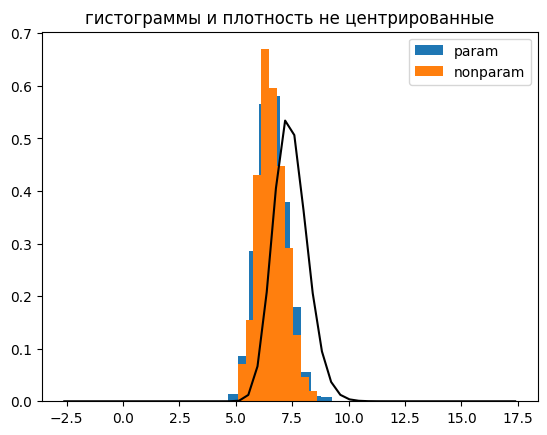

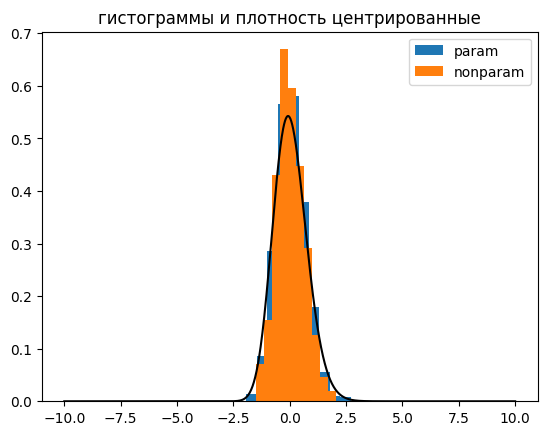

In [2]:
n = 100 #выборка иксов
N = 1000 #сколько раз считаю параметр
mu = 2
a_tetta_star = [0]*N
nonparam_a_tetta_star = [0]*N

def generator(param, n):
    return(np.random.normal(param, 1 , size = n))

def mle(x):
    return(np.mean(x))

def nonparam_generator(x):
    return(np.random.choice(x, size=np.size(x), replace=True) ) 
    

x = generator(mu, n)
tetta_hat = mle(x)

for j in range(N):
    x_star = generator(tetta_hat, n)
    a_tetta_star[j] = np.exp(mle(x_star))
    x_star = nonparam_generator(x)
    nonparam_a_tetta_star[j] = np.exp(mle(x_star))

plt.hist(a_tetta_star, density=True, label = "param")
plt.hist(nonparam_a_tetta_star, density=True, label = "nonparam")
l = np.linspace(np.exp(mu)-10,np.exp(mu)+10)
plt.plot(l, sc.stats.lognorm.pdf(l, scale = np.exp(mu), s = np.sqrt(1/n)), color = "black")
plt.legend()
plt.title("гистограммы и плотность не центрированные")
plt.show()

l_diff = np.linspace(-10, 10, 1000)
plt.plot(l_diff, sc.stats.lognorm.pdf(l_diff + np.exp(mu), scale=np.exp(mu), s=np.sqrt(1/n)), color="black")
plt.hist(a_tetta_star - np.exp(tetta_hat) , density=True, label = "param")
plt.hist(nonparam_a_tetta_star - np.exp(tetta_hat) , density=True, label = "nonparam")
plt.legend()
plt.title("гистограммы и плотность центрированные")
plt.show()

In [3]:
alpha = 0.05
def interval_based_on_estimation(alpha, tetta_hat, sigma_hat, n):
    z = sc.stats.norm.ppf(1-alpha/2, 0, sigma_hat)
    a = np.exp(tetta_hat ) - z/np.sqrt(n)
    b = np.exp(tetta_hat ) + z/np.sqrt(n)
    return [a, b]

def percentile (a, alpha, n):
    np.sort(a)
    return [ a[int(alpha*n/2)], a[int(n - alpha*n/2)] ]

def pivotal (a, alpha, n, a_tetta_hat):
    np.sort(a)
    return [2*a_tetta_hat - a[int(n - alpha*n/2)], 2*a_tetta_hat - a[int(alpha*n/2)] ]

def bootstrap_est_of_sigma(n,N,a, a_tetta_hat):
    d = 0
    for j in range(N):
        d+=(a[j] - a_tetta_hat)**2
    return np.sqrt(n/N *d)

sigma_hat = np.exp(mle(x))
exact = interval_based_on_estimation(alpha, tetta_hat, sigma_hat, n)
print("exact:", exact[0], exact[1])

intr = interval_based_on_estimation(alpha,tetta_hat,bootstrap_est_of_sigma(n,N,a_tetta_star, np.exp(tetta_hat)) , n)
print("parametric based on estimation:", intr[0], intr[1])

perc = percentile (a_tetta_star, alpha, n)
print("parametric percentile:", perc[0], perc[1])

piv = pivotal (a_tetta_star, alpha, n, np.exp(tetta_hat))
print("parametric pivotal:", piv[0], piv[1])

perc = percentile (nonparam_a_tetta_star, alpha, n)
print("nonparametric percentile:", perc[0], perc[1])

piv = pivotal (nonparam_a_tetta_star, alpha, n, np.exp(tetta_hat))
print("nonparametric pivotal:", piv[0], piv[1])


print("true tetta:", np.exp(2))

exact: 5.272297031308523 7.842810963657121
parametric based on estimation: 5.2514142741507985 7.863693720814846
parametric percentile: 5.743869403110829 7.227630578332947
parametric pivotal: 5.887477416632697 7.371238591854815
nonparametric percentile: 6.202804156516143 5.5728823117657305
nonparametric pivotal: 7.542225683199914 6.9123038384495015
true tetta: 7.38905609893065


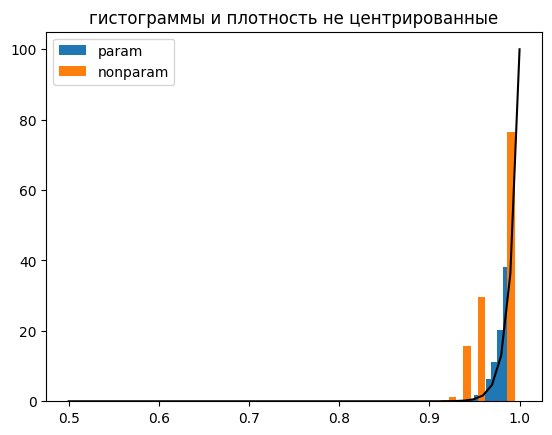

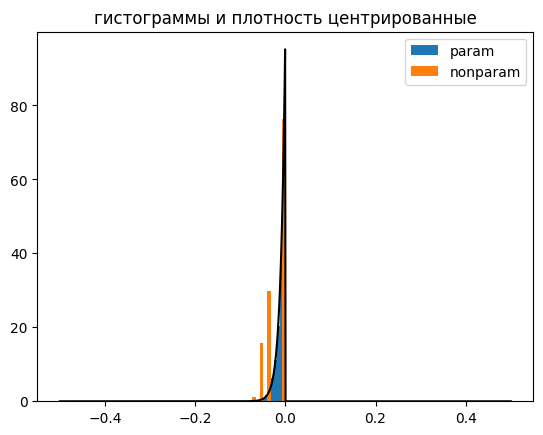

In [8]:
n = 100
N = 1000
mu = 1
def generator(param, n):
    return(np.random.uniform(0, param , size = n))

def mle(x):
    return(np.max(x))

def nonparam_generator(x):
    return(np.random.choice(x, size=np.size(x), replace=True) ) 
    
a_tetta_star = [0]*N
nonparam_a_tetta_star = [0]*N
x = generator(mu, n)
tetta_hat = mle(x)

for j in range(N):
    x_star = generator(tetta_hat, n)
    a_tetta_star[j] = mle(x_star)
    x_star = nonparam_generator(x)
    nonparam_a_tetta_star[j] = mle(x_star)


def theta_hat_pdf_beta(z):
    return sc.stats.beta.pdf(z, n, 1) 
    
plt.hist(a_tetta_star, density=True, label = "param")
plt.hist(nonparam_a_tetta_star, density=True, label = "nonparam")
l = np.linspace(0.5, mu)
plt.plot(l, theta_hat_pdf_beta(l), color = "black")
plt.legend()
plt.title("гистограммы и плотность не центрированные")
plt.show()

l_diff = np.linspace(-0.5, 0.5, 1000)
plt.plot(l_diff, theta_hat_pdf_beta(l_diff+ mu), color="black")
plt.hist(a_tetta_star - tetta_hat , density=True, label = "param")
plt.hist(nonparam_a_tetta_star - tetta_hat , density=True, label = "nonparam")
plt.legend()
plt.title("гистограммы и плотность центрированные")
plt.show()

In [5]:
alpha = 0.05
def interval_based_on_estimation(alpha, tetta_hat, n):
    q1 = sc.stats.beta.ppf(alpha/2, n, 1)
    q2 = sc.stats.beta.ppf(1-alpha/2, n, 1)
    return [ tetta_hat/q2, tetta_hat/q1]

def percentile (a, alpha, n):
    np.sort(a)
    return [ a[int(alpha*n/2)], a[int(n - alpha*n/2)] ]

def pivotal (a, alpha, n, a_tetta_hat):
    np.sort(a)
    return [2*a_tetta_hat - a[int(n - alpha*n/2)], 2*a_tetta_hat - a[int(alpha*n/2)] ]

def bootstrap_est_of_sigma(n,N,a, a_tetta_hat):
    d = 0
    for j in range(N):
        d+=(a[j] - a_tetta_hat)**2
    return np.sqrt(n/N *d)


exact = interval_based_on_estimation(alpha, tetta_hat, n)
print("exact:", exact[0], exact[1])

perc = percentile (a_tetta_star, alpha, n)
print("parametric percentile:", perc[0], perc[1])

piv = pivotal (a_tetta_star, alpha, n, tetta_hat)
print("parametric pivotal:", piv[0], piv[1])

perc = percentile (nonparam_a_tetta_star, alpha, n)
print("nonparametric percentile:", perc[0], perc[1])

piv = pivotal (nonparam_a_tetta_star, alpha, n, tetta_hat)
print("nonparametric pivotal:", piv[0], piv[1])


print("true tetta:", mu)

exact: 0.9936481130775504 1.0307260640630949
parametric percentile: 0.9706033733584118 0.9930152319146683
parametric pivotal: 0.9937779180844304 1.0161897766406869
nonparametric percentile: 0.9933965749995494 0.9557061798033925
nonparametric pivotal: 1.0310869701957062 0.9933965749995494
true tetta: 1


In [ ]:
3. Построить для медианы распределения Коши а) асимптотический интервал на основе асимпто-
тической нормальности б) непараметрический pivotal bootstrap доверительный интервал. В чем

плюс второго интервала в случае, если мы не знаем, что настоящее распределение – Коши?

In [12]:
n = 100 #выборка коши
N = 1000 #для будстрепа
tetta = 8
sigma2 = 1 / (4* (np.pi)**2)
alpha = 0.05

nonparam_tetta_star = [0]*N

def generator(param, n):
    return(sc.stats.cauchy.rvs(loc = param, size = n))

def med_est(x):
    return(np.median(x))

def nonparam_generator(x):
    return(np.random.choice(x, size=np.size(x), replace=True) ) 

def asymp_int (x, sigma2, n, alpha):
    q1 = sc.stats.norm.ppf(alpha/2, 0, np.sqrt(sigma2))
    q2 = sc.stats.norm.ppf( 1-alpha/2, 0, np.sqrt(sigma2))
    return [np.median(x) - q2/np.sqrt(n), np.median(x) - q1/np.sqrt(n)]

def pivotal (a, alpha, n, tetta_hat):
    np.sort(a)
    return [2*tetta_hat - a[int(n - alpha*n/2)], 2*tetta_hat - a[int(alpha*n/2)] ]

    
x = generator(tetta, n)
est = med_est(x)

for j in range(N):
    x_star = generator(est, n)
    nonparam_tetta_star[j] = np.median(x_star)

piv =  pivotal (nonparam_tetta_star, alpha, n, est)
asympt = asymp_int (x, sigma2, n, alpha)
print("nonparametric pivotal:", piv[0], piv[1])
print("asymptotic:", asympt[0], asympt[1])

nonparametric pivotal: 7.927677031625443 8.016102861154145
asymptotic: 7.971609950946419 8.033997542230747


In [10]:
x = np.loadtxt('sydrain.txt', skiprows=1)
alpha = 0.05
nonparam_tetta_star = [0]*N

def nonparam_generator(x):
    return(np.random.choice(x, size=np.size(x), replace=True) ) 

def pivotal (a, alpha, n, tetta_hat):
    np.sort(a)
    return [2*tetta_hat - a[int(n - alpha*n/2)], 2*tetta_hat - a[int(alpha*n/2)] ]

def percentile (a, alpha, n):
    np.sort(a)
    return [ a[int(alpha*n/2)], a[int(n - alpha*n/2)] ]

est = np.median(x)

for j in range(N):
    x_star = nonparam_generator(x)
    nonparam_tetta_star[j] = np.median(x_star)

print("median:", end="\n")
piv =  pivotal (nonparam_tetta_star, alpha, n, est)
print("nonparametric pivotal:", piv[0], piv[1])
perc =  percentile (nonparam_tetta_star, alpha, n)
print("nonparametric percentile:", perc[0], perc[1])



est = np.mean(x)

for j in range(N):
    x_star = nonparam_generator(x)
    nonparam_tetta_star[j] = np.mean(x_star)

print("mean:", end="\n")
piv =  pivotal (nonparam_tetta_star, alpha, n, est)
print("nonparametric pivotal:", piv[0], piv[1])
perc =  percentile (nonparam_tetta_star, alpha, n)
print("nonparametric percentile:", perc[0], perc[1])


median:
nonparametric pivotal: 127.29999999999998 133.1
nonparametric percentile: 133.1 138.9
mean:
nonparametric pivotal: 133.05531914893615 119.82765957446802
nonparametric percentile: 153.9936170212766 140.76595744680847
